In [1]:
import os

# Print current working directory
print(os.getcwd())

# Change to your desired directory
os.chdir('/Users/svasquez/driblab/dl-vision')
print(os.getcwd())

/Users/svasquez/driblab/dl-vision/stats/obso/run_detection
/Users/svasquez/driblab/dl-vision


In [2]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [3]:
def calculate_unknown_possession_time(possession_windows):
    possession_windows.sort(key=lambda x: x['from'])  # Ensure ordered chronologically

    total_gap = 0.0
    for i in range(len(possession_windows) - 1):
        gap = possession_windows[i + 1]['from'] - possession_windows[i]['to']

        if gap > 0:
            total_gap += gap

    return total_gap

In [4]:
path = f"/Users/svasquez/driblab/dl-vision/outputs/666385/timeline.json"

with open(path, 'r') as f:
    data = json.load(f)



gap = calculate_unknown_possession_time(data)
print(gap)

FileNotFoundError: [Errno 2] No such file or directory: '/Users/svasquez/driblab/dl-vision/outputs/666385/timeline.json'

## Check gap in possesion interval

In [6]:
path = f"/Users/svasquez/driblab/dl-vision/outputs/644676/possession_intervals.json"

with open(path, 'r') as f:
    data = json.load(f)


gap = 0

for i in range(len(data)):
    if i == len(data) - 1:
        break

    data2 = data[i+1][1]
    data1 = data[i][2]

    gap += data2 - data1

    if i == 10:
        break

    # break

print(gap)



80.73431399999997


## Check gap in new Player Possesion Interval

In [7]:
import json

path = "/Users/svasquez/driblab/dl-vision/outputs/644676/player_possessions_by_interval.json"

with open(path, 'r') as f:
    data = json.load(f)

total_gap = 0
for interval in data:
    # print(f"\n🔷 Team {interval['team_id']} | Period: {interval['period']} | Start: {interval['start_vt']} | End: {interval['end_vt']}")

    last_to = interval["start_vt"]
    for possession in interval["player_possessions"]:
        gap = round(possession["from"] - last_to, 6)
        if gap > 0:
            total_gap += gap
            # print(f"⏳ Gap of {gap:.3f} seconds between {last_to:.3f} → {possession['from']:.3f}")
        last_to = possession["to"]

print(f"Total gap: {total_gap:.3f} seconds")


Total gap: 40.869 seconds


# EDA Run Detection

In [27]:
runs_path = f"outputs/666385/666385_runs.jsonl"

runs = []

with open(runs_path, 'r') as f:
    for line in f:
        runs.append(json.loads(line))

total_runs = len(runs)
print(total_runs)

455


In [28]:
runs[375]

{'match_id': '666385',
 'run_id': '666385_375',
 'team_id': 3651,
 'player_id': 1157794,
 'ball_carrier_id_start': 1610030,
 'ball_carrier_id_end': 1157794,
 'start_frame': 46125,
 'end_frame': 46161,
 'start_timestamp': 4641.74,
 'end_timestamp': 4645.34,
 'period': 2,
 'runner_info': {'start_position': {'x': 62.0, 'y': 54.56},
  'positions': [{'x': 62.0, 'y': 54.56, 'frame': 46125, 'period': 2}],
  'metrics': {'xR_start': None,
   'xR_end': None,
   'PC_start': None,
   'PC_end': None,
   'xG_start': None,
   'xG_end': None},
  'end_position': {'x': 85.08, 'y': 53.14}},
 'possession': {'start_team': '3651', 'end_team': '3651'},
 'off_ball_teammates': [{'player_id': 38689,
   'start_position': {'x': 52.45, 'y': 23.44},
   'end_position': {'x': 83.35, 'y': 28.88},
   'metrics': {'xR_start': None,
    'xR_end': None,
    'PC_start': None,
    'PC_end': None,
    'xG_start': None,
    'xG_end': None}},
  {'player_id': 1219428,
   'start_position': {'x': 34.68, 'y': 39.08},
   'end_positi

## See how many runs dont have either ball_carrier_start and ball_carrier_end

In [8]:
and_count = 0

or_count = 0

for run in runs:
    ball_carrier_id_start = run.get('ball_carrier_id_start')
    ball_carrier_id_end = run.get('ball_carrier_id_end')

    if ball_carrier_id_start is None and ball_carrier_id_end is None:
        and_count += 1
    elif ball_carrier_id_start is None or ball_carrier_id_end is None:
        or_count += 1


print(f"Total runs: {total_runs}")
print(f"Percentage of runs without ball carrier AND: {and_count/total_runs}")
print(f"Percentage of runs without ball carrier OR: {or_count/total_runs}")
print(f"Percentage of runs without ball carrier: {(and_count + or_count)/total_runs}")

# How many runs will remain after removing runs without ball carrier?
runs_without_ball_carrier = [run for run in runs if run.get('ball_carrier_id_start') is None or run.get('ball_carrier_id_end') is None]

remaining_runs = total_runs - len(runs_without_ball_carrier)
print(f"Total runs without ball carrier: {len(runs_without_ball_carrier)}")
print(f"Total runs remaining: {remaining_runs}")







Total runs: 455
Percentage of runs without ball carrier AND: 0.024175824175824177
Percentage of runs without ball carrier OR: 0.015384615384615385
Percentage of runs without ball carrier: 0.03956043956043956
Total runs without ball carrier: 18
Total runs remaining: 437


## Check AVG duration of runs

AVG duration of runs: 9.42 seconds


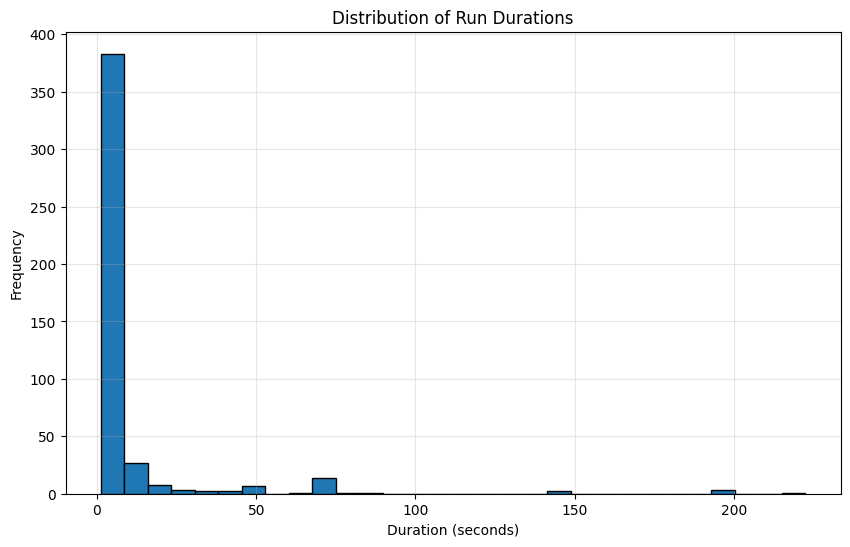

In [9]:
duration_runs = [run['end_timestamp'] - run['start_timestamp'] for run in runs]

print(f"AVG duration of runs: {sum(duration_runs) / len(duration_runs):.2f} seconds")

# Create histogram of run durations
plt.figure(figsize=(10, 6))
plt.hist(duration_runs, bins=30, edgecolor='black')
plt.title('Distribution of Run Durations')
plt.xlabel('Duration (seconds)')
plt.ylabel('Frequency')
plt.grid(True, alpha=0.3)
plt.show()



### Get the number of runs that have exactly one sec of duration

In [10]:


count = 0
for run in duration_runs:
    
    if round(run, 1) == 1.6:
        count += 1

print(f"Number of runs with exactly one sec of duration: {count}")

print(f"Percentage of runs with exactly one sec of duration: {count/total_runs}")   



Number of runs with exactly one sec of duration: 85
Percentage of runs with exactly one sec of duration: 0.18681318681318682


### Get the average distance covered by run

In [11]:
import math


distances = []
for run in runs:
    start_pos = run['runner_info']['start_position']
    end_pos = run['runner_info']['end_position']
    distance = math.sqrt((end_pos['x'] - start_pos['x'])**2 + (end_pos['y'] - start_pos['y'])**2)
    distances.append(distance)

print(runs[0])
print(f"Average distance covered by run: {sum(distances) / len(distances):.2f} meters")

{'match_id': '666385', 'run_id': '666385_0', 'team_id': 3651, 'player_id': 69811, 'ball_carrier_id_start': 69811, 'ball_carrier_id_end': 69811, 'start_frame': 169, 'end_frame': 183, 'start_timestamp': 17.9, 'end_timestamp': 19.3, 'period': 1, 'runner_info': {'start_position': {'x': 50.84, 'y': 42.5}, 'positions': [{'x': 50.84, 'y': 42.5, 'frame': 169, 'period': 1}], 'metrics': {'xR_start': None, 'xR_end': None, 'PC_start': None, 'PC_end': None, 'xG_start': None, 'xG_end': None}, 'end_position': {'x': 42.41, 'y': 49.27}}, 'possession': {'start_team': '3651', 'end_team': '3651'}, 'off_ball_teammates': [{'player_id': 151904, 'start_position': {'x': 48.13, 'y': 37.96}, 'end_position': {'x': 39.66, 'y': 42.03}, 'metrics': {'xR_start': None, 'xR_end': None, 'PC_start': None, 'PC_end': None, 'xG_start': None, 'xG_end': None}}, {'player_id': 1157794, 'start_position': {'x': 44.96, 'y': 39.19}, 'end_position': {'x': 44.4, 'y': 40.35}, 'metrics': {'xR_start': None, 'xR_end': None, 'PC_start': No

### See how many outliers we have

In [12]:
# Check runs that have a duration of more than 10 seconds
outliers = [run for run in runs if run['end_timestamp'] - run['start_timestamp'] > 10]
print(f"Total runs with duration > 10 seconds: {len(outliers)}")

# Check runs that have a duration of more than 20 seconds
outliers = [run for run in runs if run['end_timestamp'] - run['start_timestamp'] > 20]
print(f"Total runs with duration > 20 seconds: {len(outliers)}")

Total runs with duration > 10 seconds: 63
Total runs with duration > 20 seconds: 42


In [13]:
and_count = 0
or_count = 0

for run in outliers:

    ball_carrier_id_start = run.get('ball_carrier_id_start')
    ball_carrier_id_end = run.get('ball_carrier_id_end')

    if ball_carrier_id_start is None and ball_carrier_id_end is None:
        and_count += 1
    elif ball_carrier_id_start is None or ball_carrier_id_end is None:
        or_count += 1
    

print(f"Total runs with duration > 20 seconds: {len(outliers)}")
print(f"Percentage of outlier runs without ball carrier AND: {and_count/len(outliers)}")
print(f"Percentage of outlier runs without ball carrier OR: {or_count/len(outliers)}")
print(f"Percentage of outlier runs without ball carrier: {(and_count + or_count)/len(outliers)}")




Total runs with duration > 20 seconds: 42
Percentage of outlier runs without ball carrier AND: 0.2619047619047619
Percentage of outlier runs without ball carrier OR: 0.09523809523809523
Percentage of outlier runs without ball carrier: 0.35714285714285715


## Check how may runs are made by the ball carrier at the start or end

In [14]:
not_off_ball_runs = 0

for run in runs:
    ball_carrier_id_start = run.get('ball_carrier_id_start')
    ball_carrier_id_end = run.get('ball_carrier_id_end')

    plyr_id = run.get('player_id')

    if plyr_id == ball_carrier_id_start or plyr_id == ball_carrier_id_end:
        not_off_ball_runs += 1
        

        
print(f"Number of runs: {len(runs)}")
print(f"Total runs made by the ball carrier at the start or end: {not_off_ball_runs}")
print(f"Percentage of runs made by the ball carrier at the start or end: {not_off_ball_runs/len(runs)}")


    



Number of runs: 455
Total runs made by the ball carrier at the start or end: 77
Percentage of runs made by the ball carrier at the start or end: 0.16923076923076924


## Remove outliers
- runs that are missing ball_carrier_id_start or ball_carrier_id_end
- runs that take more than 20 sec

**IMPORTANT** 

Dont eliminate runs where the runner becomes the ball carrier at the end. This runs are valuable since they show how the off ball run was so good it demanded the ball

If this happens change the ball carrier at the end to be the pass giver

In [24]:
clean_runs = []

for run in runs:

    duration = run['end_timestamp'] - run['start_timestamp']

    # Get if the ball carrier is the player_id
    ball_carrier_id_start = run.get('ball_carrier_id_start')
    ball_carrier_id_end = run.get('ball_carrier_id_end')

    plyr_id = run.get('player_id')

    # Determine if the run is off ball
    off_ball:bool = False if plyr_id == ball_carrier_id_start else True

    # Check if the ball carrier at the end is the pass giver
    received_ball:bool = True if plyr_id == ball_carrier_id_end else False

    if received_ball:
        run['ball_carrier_id_end'] = run.get('ball_carrier_id_start')

    if run.get('ball_carrier_id_start') is not None and run.get('ball_carrier_id_end') is not None and duration < 20 and off_ball:
        clean_runs.append(run)


print(f"Total runs: {len(runs)}")
print(f"Total runs after removing outliers: {len(clean_runs)}")

Run 666385_0 received the ball
Run 666385_23 received the ball
Run 666385_80 received the ball
Run 666385_120 received the ball
Run 666385_123 received the ball
Run 666385_134 received the ball
Run 666385_145 received the ball
Run 666385_150 received the ball
Run 666385_166 received the ball
Run 666385_173 received the ball
Run 666385_203 received the ball
Run 666385_213 received the ball
Run 666385_217 received the ball
Run 666385_225 received the ball
Run 666385_242 received the ball
Run 666385_252 received the ball
Run 666385_277 received the ball
Run 666385_280 received the ball
Run 666385_313 received the ball
Run 666385_323 received the ball
Run 666385_328 received the ball
Run 666385_348 received the ball
Run 666385_355 received the ball
Run 666385_362 received the ball
Run 666385_431 received the ball
Run 666385_445 received the ball
Total runs: 455
Total runs after removing outliers: 370


RETURNING DEFENDERS from team 3659
RETURNING DEFENDERS from team 3659
DRAWING PITCH start
TEAM ID 3651
RETURNING PITCH CONTROL for frame 46118
0.8116030102321128
ADDING TEAMMATE 38689 -> {'x': 52.45, 'y': 23.44}
ADDING TEAMMATE 1219428 -> {'x': 34.68, 'y': 39.08}
ADDING TEAMMATE 1329659 -> {'x': 54.71, 'y': 48.95}
ADDING TEAMMATE 1263688 -> {'x': 32.11, 'y': 40.15}
ADDING TEAMMATE 45067 -> {'x': 47.73, 'y': 64.87}
ADDING TEAMMATE 1610030 -> {'x': 39.2, 'y': 43.42}
ADDING TEAMMATE 69811 -> {'x': 32.83, 'y': 40.78}
ADDING TEAMMATE 239959 -> {'x': 36.04, 'y': 33.96}
ADDING TEAMMATE 1159675 -> {'x': 30.96, 'y': 41.56}
ADDING DEFENDER 1267742 -> {'x': 50.82, 'y': 30.76, 'vis': True, 'id': 1267742}
ADDING DEFENDER 1312313 -> {'x': 45.56, 'y': 41.9, 'vis': False, 'id': 1312313}
ADDING DEFENDER 1302464 -> {'x': 31.14, 'y': 32.3, 'vis': False, 'id': 1302464}
ADDING DEFENDER 240070 -> {'x': 91.9, 'y': 37.16, 'vis': False, 'id': 240070}
ADDING DEFENDER 69834 -> {'x': 53.22, 'y': 58.44, 'vis': Tru

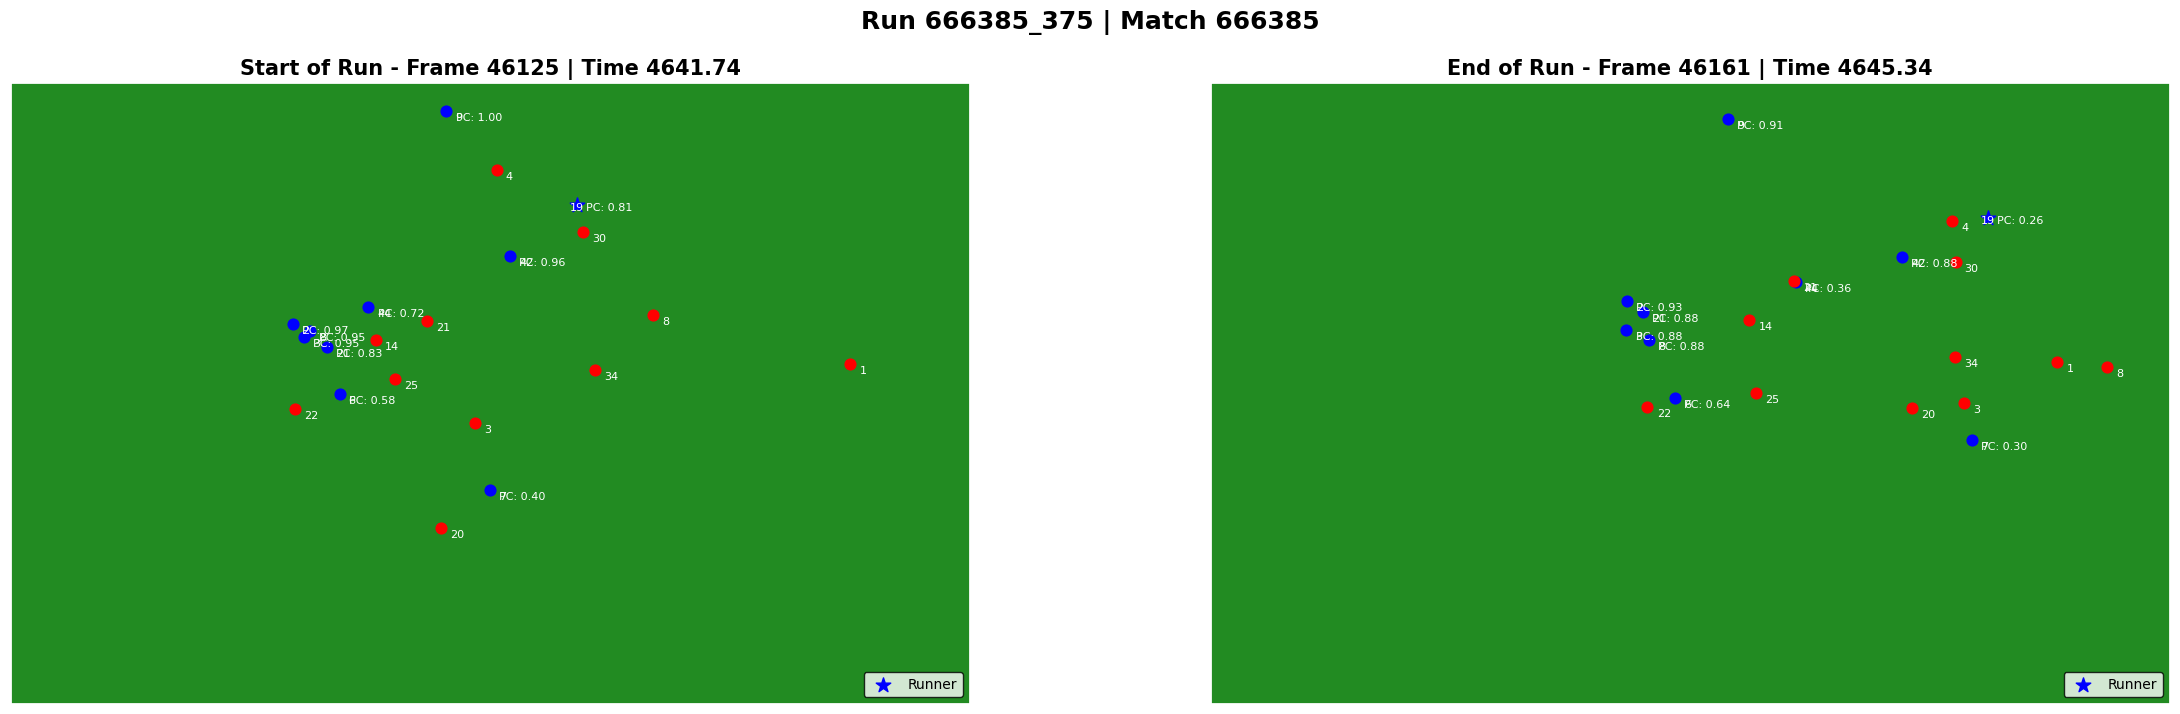

In [16]:
from stats.obso.run_detection.plot_run import PlotRun
match_id = 666385
    
pr = PlotRun(match_id)

pr.load_pitch_control()


run_id = 375
fig = pr.plot_run(pr.runs[run_id], pr.player_lookup, pc_annotate = True, def_team = True)
plt.show()


RETURNING DEFENDERS from team 3659
RETURNING DEFENDERS from team 3659
DRAWING PITCH start
TEAM ID 3651
RETURNING PITCH CONTROL for frame 46118
0.8116030102321128
ADDING TEAMMATE 38689 -> {'x': 52.45, 'y': 23.44}
ADDING TEAMMATE 1219428 -> {'x': 34.68, 'y': 39.08}
ADDING TEAMMATE 1329659 -> {'x': 54.71, 'y': 48.95}
ADDING TEAMMATE 1263688 -> {'x': 32.11, 'y': 40.15}
ADDING TEAMMATE 45067 -> {'x': 47.73, 'y': 64.87}
ADDING TEAMMATE 1610030 -> {'x': 39.2, 'y': 43.42}
ADDING TEAMMATE 69811 -> {'x': 32.83, 'y': 40.78}
ADDING TEAMMATE 239959 -> {'x': 36.04, 'y': 33.96}
ADDING TEAMMATE 1159675 -> {'x': 30.96, 'y': 41.56}
ADDING DEFENDER 1267742 -> {'x': 50.82, 'y': 30.76, 'vis': True, 'id': 1267742}
ADDING DEFENDER 1312313 -> {'x': 45.56, 'y': 41.9, 'vis': False, 'id': 1312313}
ADDING DEFENDER 1302464 -> {'x': 31.14, 'y': 32.3, 'vis': False, 'id': 1302464}
ADDING DEFENDER 240070 -> {'x': 91.9, 'y': 37.16, 'vis': False, 'id': 240070}
ADDING DEFENDER 69834 -> {'x': 53.22, 'y': 58.44, 'vis': Tru

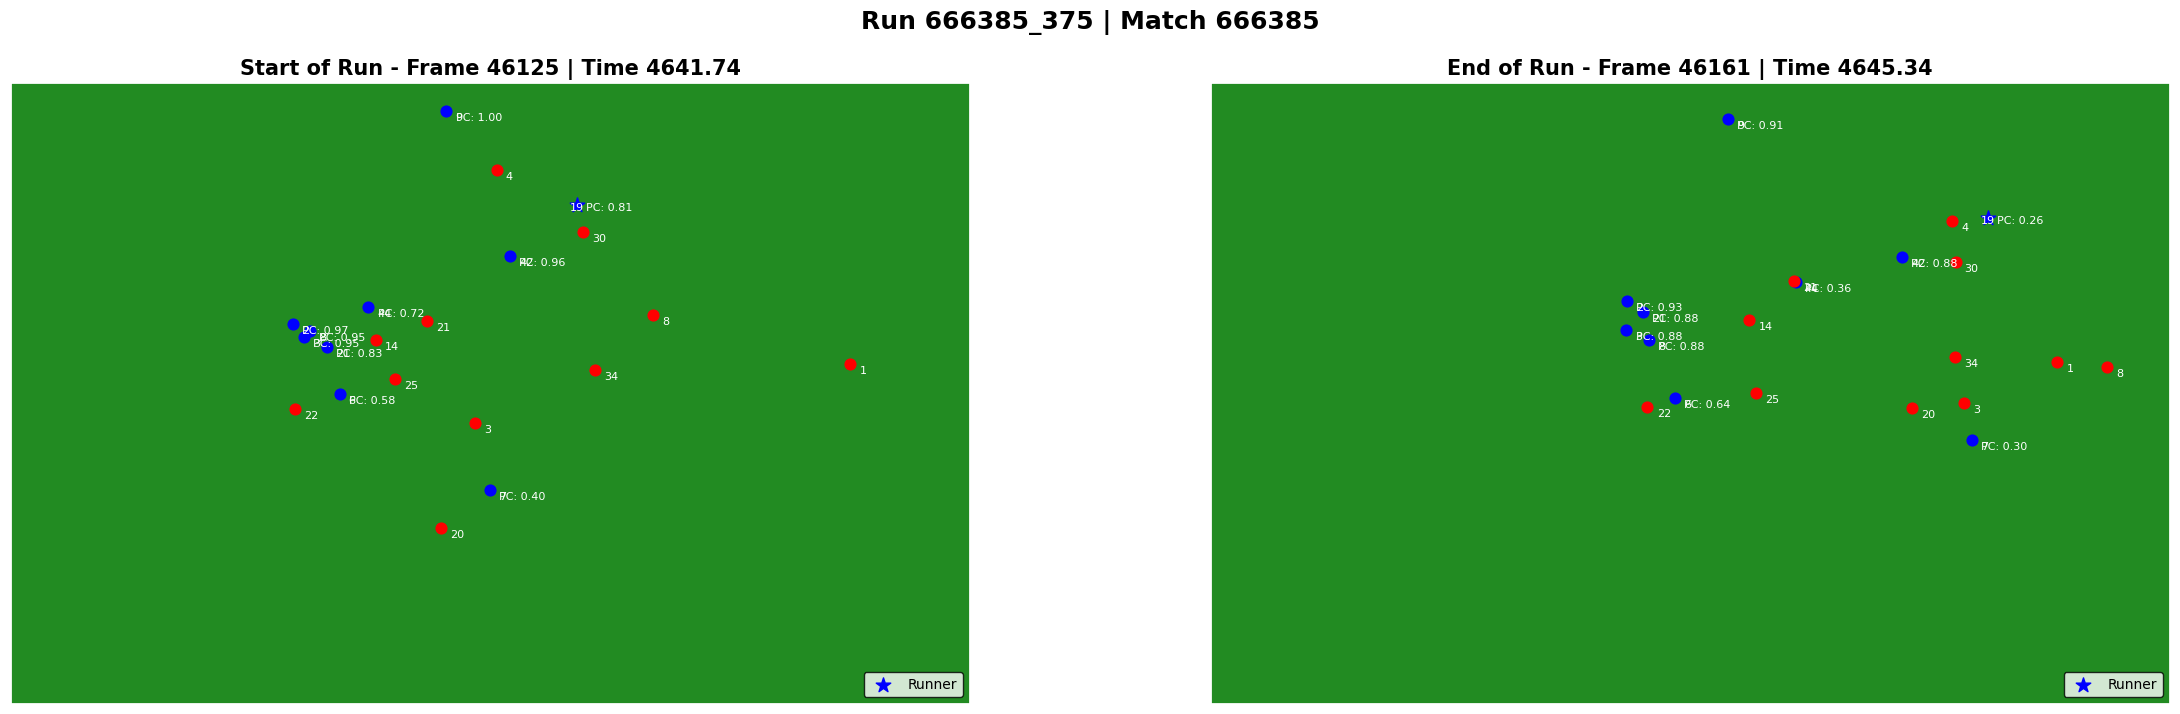

In [20]:
run_id = 375
fig = pr.plot_run(pr.runs[run_id], pr.player_lookup, pc_annotate = True, def_team = True)
plt.show()

In [21]:
runs[375]

{'match_id': '666385',
 'run_id': '666385_375',
 'team_id': 3651,
 'player_id': 1157794,
 'ball_carrier_id_start': 1610030,
 'ball_carrier_id_end': 1157794,
 'start_frame': 46125,
 'end_frame': 46161,
 'start_timestamp': 4641.74,
 'end_timestamp': 4645.34,
 'period': 2,
 'runner_info': {'start_position': {'x': 62.0, 'y': 54.56},
  'positions': [{'x': 62.0, 'y': 54.56, 'frame': 46125, 'period': 2}],
  'metrics': {'xR_start': None,
   'xR_end': None,
   'PC_start': None,
   'PC_end': None,
   'xG_start': None,
   'xG_end': None},
  'end_position': {'x': 85.08, 'y': 53.14}},
 'possession': {'start_team': '3651', 'end_team': '3651'},
 'off_ball_teammates': [{'player_id': 38689,
   'start_position': {'x': 52.45, 'y': 23.44},
   'end_position': {'x': 83.35, 'y': 28.88},
   'metrics': {'xR_start': None,
    'xR_end': None,
    'PC_start': None,
    'PC_end': None,
    'xG_start': None,
    'xG_end': None}},
  {'player_id': 1219428,
   'start_position': {'x': 34.68, 'y': 39.08},
   'end_positi